# Bernoulli, valeurs de zêta aux négatifs et Todd genus arithmétique

Grain **R-13** de la série [Riemann 200](README.md) (EPIC [#20403](https://github.com/jsboige/CoursIA/issues/20403), issue [#25100](https://github.com/jsboige/CoursIA/issues/25100)).

Les carnets 01 à 12 ont couvert le mémoire de 1859, la formule explicite, les surfaces, le mémoire de 1860, Riemann–Roch et les zéros — jamais les **valeurs de ζ aux entiers négatifs** ni les **nombres de Bernoulli**. Ce carnet ouvre ce versant. Il est distillé de l'interview de Christophe Soulé par Pierre Pansu (IHES, 2026) : le fil va des dénominateurs de Bernoulli aux sous-groupes finis de $SL_n(\mathbb{Z})$, du Todd genus à Riemann–Roch, puis à la théorie d'Arakelov — où ce ne sont plus les valeurs de ζ mais **ses dérivées** qui apparaissent.

**Statuts, déclarés une fois pour toutes** (convention [#3801](https://github.com/jsboige/CoursIA/issues/3801)) :

- **Mesuré** : tout ce que ce carnet exécute — Bernoulli exacts, von Staudt–Clausen terme à terme, ζ(−n), le ratio ζ′(−2n)/ζ(2n+1), la série de Todd.
- **Cité** : tout ce que l'interview raconte et que nous ne re-prouvons pas — Arakelov, $K_{22}(\mathbb{Z})$ et le 691, le calcul de Zagier, Riemann–Roch arithmétique. Un témoignage daté, jamais une preuve.

Source archivée, relue avant écriture : `G:\Mon Drive\MyIA\IA\Bibliographie IA\NumberTheory\2026 - IHES & Soule - An Interview with Christophe Soule (Pierre Pansu, ihes.fr interview-soule).html` (toute citation de l'interview ci-dessous y a été vérifiée verbatim).

## Plan

1. **Bernoulli exacts** : la récursion définissante en rationnels exacts, $B_0 \dots B_{32}$, la nullité des impairs.
2. **Von Staudt–Clausen** : $B_{2k} + \sum_{p-1 \mid 2k} 1/p \in \mathbb{Z}$, chaque dénominateur nommé par son premier — la lecture que Soulé fait remonter à Minkowski et Burnside.
3. **ζ aux entiers négatifs** : la formule d'Euler $\zeta(1-n) = -B_n/n$ mesurée contre `mpmath.zeta`, zéros triviaux compris.
4. **La porte d'Arakelov** : $\zeta'(-2n)/\zeta(2n+1)$, une constante exacte — « ce ne sont pas seulement les valeurs de la fonction zêta qui apparaissent, mais les valeurs de sa dérivée ».
5. **Todd genus** : la série de Bernoulli de Riemann–Roch, mesurée contre sa forme fermée, et la tour historique vers le Riemann–Roch arithmétique (récit **cité**).
6. **Le 691, deux visages** : numérateur de $B_{12}$ mesuré ici, élément d'ordre 691 dans $K_{22}(\mathbb{Z})$ cité, congruence $\tau(n) \equiv \sigma_{11}(n)$ renvoyée à Serre 100.
7. **Grounding Mathlib** : ce qui existe (cité aux lignes du pin), ce qui n'existe pas (dit tel quel) ; exercices.

In [1]:
# Dependances : stdlib (fractions, math) + mpmath -- exception declaree de la serie
# (conventions du README : R-01/R-02 et R-12 l'ont deja ouverte). Figures : matplotlib.
from fractions import Fraction
from math import comb, factorial
import mpmath as mp
import matplotlib
import matplotlib.pyplot as plt

mp.mp.dps = 40  # chiffres significatifs pour zeta et sa derivee
print("mpmath", mp.__version__, "| dps =", mp.mp.dps)

mpmath 1.3.0 | dps = 40


In [2]:
# Pre-enregistrement H1-H3 (les predictions sont fixees AVANT les mesures ci-dessous).
HYPOTHESES = {
    "H1": ("von Staudt-Clausen exact pour k = 1..16 : B_{2k} + somme des 1/p sur les premiers "
           "p tels que (p-1) | 2k est un ENTIER, et le denominateur reduit de B_{2k} est "
           "EXACTEMENT le produit de ces premiers. Arithmetique rationnelle exacte. "
           "Prediction : CONFIRMEE sur les 16 lignes."),
    "H2": ("zeta(-n) = -B_{n+1}/(n+1) pour n = 1..15 : |erreur| < 1e-30 a dps = 40 "
           "contre mpmath.zeta. Prediction : CONFIRMEE (les zeros triviaux tombent comme "
           "cas particuliers B_impair = 0)."),
    "H3": ("zeta'(-2n) / zeta(2n+1) = (-1)^n (2n)! / (2 (2 pi)^{2n}) pour n = 1..6 : "
           "erreur relative < 1e-12, signe (=-1)^n compris. Risque annonce : la constante "
           "decroit vite ((2n)!/(2 pi)^{2n}), mais n = 6 reste dans la portee de dps = 40. "
           "Si le seuil tombe, REFUTEE reste dans la sortie, pas habillee."),
}
for k, v in HYPOTHESES.items():
    print(k, "--", v)

H1 -- von Staudt-Clausen exact pour k = 1..16 : B_{2k} + somme des 1/p sur les premiers p tels que (p-1) | 2k est un ENTIER, et le denominateur reduit de B_{2k} est EXACTEMENT le produit de ces premiers. Arithmetique rationnelle exacte. Prediction : CONFIRMEE sur les 16 lignes.
H2 -- zeta(-n) = -B_{n+1}/(n+1) pour n = 1..15 : |erreur| < 1e-30 a dps = 40 contre mpmath.zeta. Prediction : CONFIRMEE (les zeros triviaux tombent comme cas particuliers B_impair = 0).
H3 -- zeta'(-2n) / zeta(2n+1) = (-1)^n (2n)! / (2 (2 pi)^{2n}) pour n = 1..6 : erreur relative < 1e-12, signe (=-1)^n compris. Risque annonce : la constante decroit vite ((2n)!/(2 pi)^{2n}), mais n = 6 reste dans la portee de dps = 40. Si le seuil tombe, REFUTEE reste dans la sortie, pas habillee.


## 1. Les nombres de Bernoulli, exacts

Le point de départ est la récursion définissante (convention $B_1 = -1/2$, celle de Mathlib `bernoulli`) :

$$\sum_{k=0}^{n} \binom{n+1}{k} B_k = 0 \quad (n \geq 1),$$

forme équivalente au théorème `sum_bernoulli` de Mathlib : $\sum_{k<n} \binom{n}{k} B_k = 1$ si $n = 1$, $0$ sinon ([`Bernoulli.lean:226`](https://github.com/leanprover-community/mathlib4/blob/master/Mathlib/NumberTheory/Bernoulli.lean)). On la résout en **rationnels exacts** — aucun flottant dans cette section : chaque $B_n$ est un `Fraction` réduit, numérateur et dénominateur exacts.

Deux structures à lire dans la table : la **nullité des impairs** ($B_3 = B_5 = \dots = 0$, c'est `bernoulli_eq_zero_of_odd`, [`Bernoulli.lean:214`](https://github.com/leanprover-community/mathlib4/blob/master/Mathlib/NumberTheory/Bernoulli.lean)), et la croissance rapide des numérateurs pairs — $B_{12}$ porte déjà le fameux $691$.

In [3]:
# Recursion definissante, en Fraction exacts : B_n = -(1/(n+1)) * somme_{k<n} C(n+1,k) B_k.
N_MAX = 32
B = [Fraction(1)]                                   # B_0 = 1
for n in range(1, N_MAX + 1):
    acc = Fraction(0)
    for k in range(n):
        acc += Fraction(comb(n + 1, k)) * B[k]
    B.append(-acc / (n + 1))

impairs_testes = [n for n in range(2, N_MAX + 1) if n % 2 == 1]
impairs_non_nuls = [n for n in impairs_testes if B[n] != 0]
print(f"B_0..B_{N_MAX} calcules en rationnels exacts ({len(B)} valeurs).")
print(f"Nullite des B impairs > 1 : {len(impairs_non_nuls)} violation sur {len(impairs_testes)} "
      f"impairs testes (Mathlib bernoulli_eq_zero_of_odd).")
for n in [1, 2, 4, 6, 10, 12]:
    print(f"  B_{n:<2} = {B[n]}")

B_0..B_32 calcules en rationnels exacts (33 valeurs).
Nullite des B impairs > 1 : 0 violation sur 15 impairs testes (Mathlib bernoulli_eq_zero_of_odd).
  B_1  = -1/2
  B_2  = 1/6
  B_4  = -1/30
  B_6  = 1/42
  B_10 = 5/66
  B_12 = -691/2730


## 2. Von Staudt–Clausen : chaque dénominateur nommé par son premier

> « For me, it all began with the connection between Bernoulli numbers and finite subgroups of $SL_n(\mathbb{Z})$. The orders of these groups are related to the denominators of Bernoulli numbers. This observation goes back to Minkowski and Burnside and also appears as an exercise in Bourbaki. » — C. Soulé (interview, **cité** ; l'exercice en question : Bourbaki, *Groupes et Algèbres de Lie*, ch. III, exercices 6–8)

Le théorème de von Staudt–Clausen dit que $B_{2k} + \sum_{p-1 \mid 2k} \frac{1}{p}$ est un **entier** (la somme porte sur les premiers $p$ tels que $p-1$ divise $2k$) — c'est exactement l'énoncé `vonStaudt_clausen` de Mathlib ([`Bernoulli.lean:665`](https://github.com/leanprover-community/mathlib4/blob/master/Mathlib/NumberTheory/Bernoulli.lean)). Sa lecture complémentaire, classique : le **dénominateur réduit** de $B_{2k}$ est exactement le **produit de ces premiers**. Mathlib porte la forme d'intégralité ; la forme « dénominateur exact » n'y a pas d'énoncé public dédié — nous la **mesurons**.

In [4]:
# Von Staudt-Clausen, mesure terme a terme : integrality (Mathlib) + denominateur exact (classique, mesure).


def premiers_jusqua(m):
    return [p for p in range(2, m + 1) if all(p % d for d in range(2, int(p ** 0.5) + 1))]


h1_violations = 0
print(f"{'2k':>4} {'premiers p (p-1)|2k':<26} {'B_2k + somme 1/p':<12} entier ?  den(B_2k) = produit ?")
for k in range(1, 17):
    ps = [p for p in premiers_jusqua(2 * k + 1) if (2 * k) % (p - 1) == 0]
    total = B[2 * k] + sum(Fraction(1, p) for p in ps)
    prod = 1
    for p in ps:
        prod *= p
    ok_int = (total.denominator == 1)
    ok_den = (B[2 * k].denominator == prod)
    if not (ok_int and ok_den):
        h1_violations += 1
    print(f"{2 * k:>4} {str(ps):<26} {str(total):<12} {str(ok_int):<8}  {ok_den}")
print(f"\nH1 : {16 - h1_violations}/16 lignes conformes (entier ET denominateur = produit des premiers).")

  2k premiers p (p-1)|2k        B_2k + somme 1/p entier ?  den(B_2k) = produit ?
   2 [2, 3]                     1            True      True
   4 [2, 3, 5]                  1            True      True
   6 [2, 3, 7]                  1            True      True
   8 [2, 3, 5]                  1            True      True
  10 [2, 3, 11]                 1            True      True
  12 [2, 3, 5, 7, 13]           1            True      True
  14 [2, 3]                     2            True      True
  16 [2, 3, 5, 17]              -6           True      True
  18 [2, 3, 7, 19]              56           True      True
  20 [2, 3, 5, 11]              -528         True      True
  22 [2, 3, 23]                 6193         True      True
  24 [2, 3, 5, 7, 13]           -86579       True      True
  26 [2, 3]                     1425518      True      True
  28 [2, 3, 5, 29]              -27298230    True      True
  30 [2, 3, 7, 11, 31]          601580875    True      True
  32 [2, 3, 5, 17] 

## 3. ζ aux entiers négatifs : la formule d'Euler, mesurée

> « Bernoulli numbers are also related to the values of the Riemann zeta function at negative odd integers. » — C. Soulé (interview, **cité**)

La formule d'Euler prolonge ζ aux négatifs par les Bernoulli :

$$\zeta(1-n) = -\frac{B_n}{n},$$

avec $B_1 = -1/2$. Trois lectures dans la même table : $\zeta(-1) = -B_2/2 = -1/12$ (la valeur célèbre), les **zéros triviaux** $\zeta(-2k) = -B_{2k+1}/(2k+1) = 0$ par nullité des Bernoulli impairs, et les valeurs non nulles $\zeta(-(2k-1)) = -B_{2k}/(2k)$ — le « negative odd integers » de la citation. La mesure confronte la valeur exacte (Fraction) à `mpmath.zeta` en haute précision.

In [5]:
# H2 : zeta(-n) mesure (mpmath, dps 40) contre la valeur exacte portee par Bernoulli.
print(f"{'n':>3} {'zeta(-n) [mpmath]':<24} {'-B_{n+1}/(n+1) [exact]':<24} {'|erreur|':<10}")
h2_max_err = mp.mpf(0)
for n in range(1, 16):
    zs = mp.zeta(-n)
    exact = -B[n + 1] / (n + 1)                    # Fraction exacte
    ex = mp.mpf(exact.numerator) / mp.mpf(exact.denominator)
    err = abs(zs - ex)
    h2_max_err = max(h2_max_err, err)
    print(f"{n:>3} {mp.nstr(zs, 16):<24} {str(exact):<24} {mp.nstr(err, 3):<10}")
print(f"\nzeta(-1) = {mp.zeta(-1)}  (les zeros triviaux zeta(-2), zeta(-4), ... sont les lignes nulles de la table)")
print(f"H2 : erreur max sur n = 1..15 : {mp.nstr(h2_max_err, 3)} (seuil 1e-30)")

  n zeta(-n) [mpmath]        -B_{n+1}/(n+1) [exact]   |erreur|  
  1 -0.08333333333333333     -1/12                    0.0       
  2 0.0                      0                        0.0       
  3 0.008333333333333333     1/120                    0.0       
  4 0.0                      0                        0.0       
  5 -0.003968253968253968    -1/252                   0.0       
  6 0.0                      0                        0.0       
  7 0.004166666666666667     1/240                    0.0       
  8 0.0                      0                        0.0       
  9 -0.007575757575757576    -1/132                   0.0       
 10 0.0                      0                        0.0       
 11 0.02109279609279609      691/32760                0.0       
 12 0.0                      0                        0.0       
 13 -0.08333333333333333     -1/12                    0.0       
 14 0.0                      0                        0.0       
 15 0.4432598039215686   

## 4. La porte d'Arakelov : ζ′ aux négatifs pairs

> « Later, while working on Arakelov theory, I encountered the values of the derivative of the zeta function at negative odd integers. [...] The fact that these numbers reappear through the zeta function in Arakelov theory shows that this theory is finer than ordinary topological theory: **it is not merely the values of the zeta function that appear, but the values of its derivative**. » — C. Soulé (interview, **cité**)

L'équation fonctionnelle $\zeta(s) = 2^s \pi^{s-1} \sin(\pi s/2)\, \Gamma(1-s)\, \zeta(1-s)$ donne, en linéarisant près du zéro trivial $s_0 = -2n$ (seul le facteur $\sin$ varie au premier ordre, sa dérivée y vaut $\frac{\pi}{2}(-1)^n$) :

$$\frac{\zeta'(-2n)}{\zeta(2n+1)} = (-1)^n \, \frac{(2n)!}{2\,(2\pi)^{2n}}.$$

La dérivée aux **négatifs pairs** s'exprime par la valeur aux **impairs positifs** — les $\zeta(3), \zeta(5), \dots$ qui n'ont pas de forme fermée connue. C'est cette constant exacte que la mesure H3 confronte à `mpmath.zeta(s, derivative=1)`.

In [6]:
# H3 : le ratio de la derivee aux negatifs pairs sur la valeur aux impairs positifs.
print(f"{'n':>3} {'zeta_prime(-2n)':<22} {'ratio/zeta(2n+1)':<22} {'signe':<7} {'err relative':<12}")
h3_max_rel = mp.mpf(0)
h3_signes_ok = True
for n in range(1, 7):
    zp = mp.zeta(-2 * n, derivative=1)
    ratio = zp / mp.zeta(2 * n + 1)
    cst = mp.mpf(factorial(2 * n)) / (2 * (2 * mp.pi) ** (2 * n))
    rel = abs(abs(ratio) / cst - 1)
    signe = "-" if ratio < 0 else "+"
    attendu = "-" if n % 2 == 1 else "+"
    h3_max_rel = max(h3_max_rel, rel)
    h3_signes_ok = h3_signes_ok and (signe == attendu)
    print(f"{n:>3} {mp.nstr(zp, 12):<22} {mp.nstr(ratio, 12):<22} {signe}={attendu}   {mp.nstr(rel, 3):<12}")
print(f"\nH3 : erreur relative max sur n = 1..6 : {mp.nstr(h3_max_rel, 3)} (seuil 1e-12)")
print(f"H3 : correspondance des signes (=-1)^n : {'OK sur les 6 lignes' if h3_signes_ok else 'VIOLEE (voir la table)'}")

  n zeta_prime(-2n)        ratio/zeta(2n+1)       signe   err relative
  1 -0.0304484570584       -0.0253302959106       -=-   0.0         
  2 0.00798381145027       0.00769948669101       +=+   0.0         
  3 -0.00589975914352      -0.00585090828729      -=-   0.0         
  4 0.0083161619856        0.00829949334271       +=+   0.0         
  5 -0.0189299263381       -0.0189205760051       -=-   4.59e-41    
  6 0.0632705833415        0.063262820149         +=+   2.3e-41     

H3 : erreur relative max sur n = 1..6 : 4.59e-41 (seuil 1e-12)
H3 : correspondance des signes (=-1)^n : OK sur les 6 lignes


## 5. Todd genus : la série de Bernoulli de Riemann–Roch

> « Indeed, the formal power series defining the Todd class in the Riemann–Roch theorem involves all the Bernoulli numbers. » — C. Soulé (interview, **cité**)

La série de Todd :

$$\mathrm{Td}(x) = \frac{x}{1 - e^{-x}} = \sum_{n \geq 0} (-1)^n B_n \frac{x^n}{n!},$$

avec $B_1 = -1/2$ (la convention de ce carnet) : $\mathrm{Td}(x) = 1 + \frac{x}{2} + \frac{x^2}{12} - \frac{x^4}{720} + \dots$ On la somme **terme à terme sur les Bernoulli exacts** et on confronte à la forme fermée — le rayon de convergence est $2\pi$, la décroissance factorielle $1/n!$ domine la croissance des $B_n$ bien avant.

    x Td ferme               Td serie (N=14)        |erreur|  
  0.5 1.270747041268399      1.270747041268398      8.12e-16  
  1.0 1.581976706869326      1.581976706856274      1.31e-11  
  2.0 2.313035285499331      2.313035086410748      1.99e-7   
  3.0 3.157187089473768      3.157134963808513      5.21e-5   


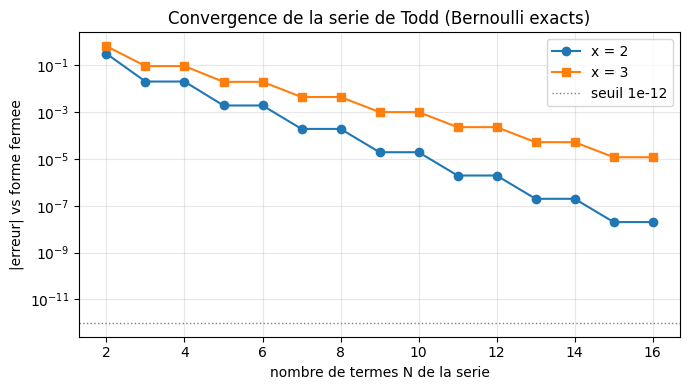

In [7]:
# La serie de Todd, term a terme sur les Bernoulli exacts, contre la forme fermee.
def todd_ferme(x):
    return x / (1 - mp.e ** (-x))


def todd_serie(x, N):
    s = mp.mpf(0)
    for n in range(N):
        bn = mp.mpf(B[n].numerator) / mp.mpf(B[n].denominator)
        s += mp.mpf((-1) ** n) * bn * mp.mpf(x) ** n / mp.mpf(factorial(n))
    return s


print(f"{'x':>5} {'Td ferme':<22} {'Td serie (N=14)':<22} {'|erreur|':<10}")
for x in [mp.mpf("0.5"), mp.mpf(1), mp.mpf(2), mp.mpf(3)]:
    ferme = todd_ferme(x)
    serie = todd_serie(x, 14)
    print(f"{mp.nstr(x, 4):>5} {mp.nstr(ferme, 16):<22} {mp.nstr(serie, 16):<22} {mp.nstr(abs(ferme - serie), 3):<10}")

# Convergence : erreur vs nombre de termes, pour x = 2 et x = 3 (le bord x -> 2*pi durcit la coupe).
plt.figure(figsize=(7, 4))
Ns = list(range(2, 17))
for x, style in [(2, "o-"), (3, "s-")]:
    errs = [abs(todd_ferme(mp.mpf(x)) - todd_serie(mp.mpf(x), N)) for N in Ns]
    plt.semilogy(Ns, [float(e) for e in errs], style, label=f"x = {x}")
plt.axhline(1e-12, color="gray", linestyle=":", linewidth=1, label="seuil 1e-12")
plt.xlabel("nombre de termes N de la serie")
plt.ylabel("|erreur| vs forme fermee")
plt.title("Convergence de la serie de Todd (Bernoulli exacts)")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

### La tour Riemann–Roch, du mémoire de 1857 à l'Arakelov (récit **cité**)

R-11 a mesuré le théorème de 1857 sur les courbes $y^2 = P(x)$. Le reste de la tour est un récit que l'interview porte — rien de ce qui suit n'est mesuré ici :

```mermaid
flowchart TD
    A["Riemann 1857 + Roch 1865<br/>Riemann-Roch sur les courbes<br/>(mesure dans R-11)"] --> B["Hirzebruch, années 1950<br/>Todd genus topologique"]
    B --> C["Grothendieck-Hirzebruch<br/>GRR, fibres vectoriels"]
    C --> D["Faltings 1983<br/>Calculus on Arithmetic Surfaces"]
    D --> E["Manin 1984<br/>programme RR arithmetique"]
    E --> F["Gillet-Soule, ~10 ans<br/>RR arithmetique en dimension quelconque"]
    F --> G["Bismut 1992<br/>torsion analytique<br/>(formulation definitive)"]
    F --> H["Zagier, appendice<br/>Stirling, serie en zeta'(s)<br/>(6 pages manuscrites, Bonn)"]
```

Deux détails que l'interview donne et que le diagramme résume : le calcul de Zagier (« two pages on his desk [...] five days later, he returned six handwritten pages ») a produit **la série en la dérivée de ζ** qui a permis de prouver le RR arithmétique conjecturé ; et le premier calcul du Todd genus arithmétique s'est fait **avec un ordinateur** — Mestre et Soulé essayant les signes d'un polynôme (« let's try one last possibility and then go for a drink [...] miraculously, we obtained a beautiful result »). L'interview situe l'usage de Maple et Maxima par Soulé à cette période en 1987-88 ; **Bonn n'appartient pas à cet épisode** : c'est celui de l'Arbeitstagung où Soulé, avec l'aide de Maxima, confiait à Zagier deux nombres définis pour tout entier n (nœud « Zagier » du diagramme). Ce carnet fait, en miniature et sans l'enjeu, ce qu'ils faisaient : sommer la série et regarder.

## 6. Le 691, deux visages

> « In my thesis, I thus showed that $K_{22}(\mathbb{Z})$ contains an element of order 691, which is the numerator of the twelfth Bernoulli number. » — C. Soulé (interview, **cité** ; thèse d'État 1978, *Groupes arithmétiques et K-théorie des anneaux d'entiers de corps de nombres*)

Le même entier vit deux vies indépendantes :

- **Ici (mesuré)** : $B_{12} = -691/2730$, où $691$ est le numérateur et $2730 = 2 \cdot 3 \cdot 5 \cdot 7 \cdot 13$ exactement le produit des premiers $p$ avec $p - 1 \mid 12$ — von Staudt–Clausen pour $k = 6$.
- **En K-théorie (cité)** : l'ordre d'un élément de $K_{22}(\mathbb{Z})$, exemple des conjectures de Lichtenbaum (les ordres des groupes de K-théorie prédits par les Bernoulli — c'est Loday qui les a présentées à Soulé, ICM Vancouver 1974).
- **Côté formes modulaires (mesuré dans une autre série)** : $\tau(n) \equiv \sigma_{11}(n) \pmod{691}$ — le carnet [Serre 100-09](../Serre100/09-congruences-tau-lacunarite-delta.ipynb) mesure cette congruence de Ramanujan. Le pont entre les deux visages (Bernoulli ↔ τ) n'est pas démontré ici : il vit dans la théorie, pas dans ce carnet.

Et pour boucler la boucle des dénominateurs : Sullivan avait montré en note aux CRAS que la classe d'Euler de $SL_n(\mathbb{Z})$ est annihilée par le dénominateur du $n$-ième nombre de Bernoulli (interview, **cité**) — c'est en allant voir Sullivan à propos de cette note que le jeune Soulé s'est fait dire : « You and I do not have the same conception of mathematics. »

In [8]:
# 691 : le numerateur de B_12 en exact, et la ligne von Staudt qui le porte.
print("B_12 =", B[12])
print("Numerateur :", B[12].numerator, "| premier ?",
      all(691 % d for d in range(2, int(691 ** 0.5) + 1)))
ps12 = [p for p in premiers_jusqua(13) if 12 % (p - 1) == 0]
total12 = B[12] + sum(Fraction(1, p) for p in ps12)
prod12 = 1
for p in ps12:
    prod12 *= p
print(f"von Staudt k = 6 : premiers {ps12}, produit {prod12} = denominateur de B_12 : "
      f"{B[12].denominator == prod12} ; B_12 + somme 1/p = {total12} (entier : {total12.denominator == 1})")
print("Face K-theorie  : K_22(Z) contient un element d'ordre 691            [Cite -- these Soulé 1978, interview]")
print("Face modulaire  : tau(n) = sigma_11(n) mod 691                       [Mesuree dans Serre100-09]")

B_12 = -691/2730
Numerateur : -691 | premier ? True
von Staudt k = 6 : premiers [2, 3, 5, 7, 13], produit 2730 = denominateur de B_12 : True ; B_12 + somme 1/p = 1 (entier : True)
Face K-theorie  : K_22(Z) contient un element d'ordre 691            [Cite -- these Soulé 1978, interview]
Face modulaire  : tau(n) = sigma_11(n) mod 691                       [Mesuree dans Serre100-09]


## 7. Grounding Mathlib — ce qui existe, ce qui n'existe pas

Conventions de la série : chaque grain cite ce qui existe dans Mathlib (fichier et ligne, au pin du lake local `formal_logic_lean`, Mathlib `0df444a360`, 2026-08-21) et dit tel quel ce qui n'existe pas.

**Existe, et c'est ce carnet** :

| Énoncé | Mathlib | Ligne |
|---|---|---|
| $\sum_{k<n} \binom{n}{k} B_k = \delta_{n,1}$ (la récursion définissante, $B_1 = -1/2$) | `NumberTheory/Bernoulli.lean` → `sum_bernoulli` | 226 |
| $B_n = 0$ pour $n$ impair $> 1$ | `bernoulli_eq_zero_of_odd` | 214 |
| Valeurs explicites $B_0..B_4$ (convention $B_1' = +1/2$ via `bernoulli'`) | `bernoulli'_zero..four` | 115–135 |
| $B_{2k} + \sum_{p-1 \mid 2k} 1/p \in \mathbb{Z}$ (von Staudt–Clausen) | `vonStaudt_clausen` | 665 |
| $\zeta$ aux **entiers positifs** via polynômes de Bernoulli | `NumberTheory/ZetaValues.lean` → `hasSum_zeta_nat`, `hasSum_zeta_two`, `hasSum_zeta_four` | 430, 452, 457 |

**N'existe pas** (greps à vide au pin, vérifiés à la rédaction) :

- $\zeta(1-n) = -B_n/n$ : aucune valeur de ζ aux entiers négatifs dans Mathlib — `ZetaValues.lean` s'arrête aux positifs (sa seule ligne « Bernoulli » est le docstring qui annonce la forme aux positifs) ;
- tout `*ToddGenus*` ou `*RiemannRoch*` : absent du pin (déjà relevé par R-11) ;
- la forme « dénominateur réduit de $B_{2k}$ = produit des premiers » : pas d'énoncé public dédié (les lemmes privés de `Bernoulli.lean` l.440–476 en sont la machinerie).

Le versant de ce carnet — Bernoulli calculés, ζ aux négatifs, Todd — est donc pour l'instant **hors Mathlib** : ce que le carnet mesure, la bibliothèque ne le formalise pas encore. La partie preuve du versant (von Staudt–Clausen) existe, elle.

## Exercices

Trois exercices, à compléter dans les cellules suivantes — le carnet s'exécute de bout en bout même non complété (convention C.1).

In [9]:
# Exercice 1 -- Etendre la table : B_34 et B_36, von Staudt pour k = 17 et k = 18.
# Etape 1 : prolonger la liste B jusqu a l indice 36 (meme recurrence, N_MAX = 36).
# Etape 2 : pour k = 17 puis 18, lister les premiers p tels que (p-1) | 2k, verifier que
#           B_{2k} + somme des 1/p est un entier ET que le denominateur reduit egale leur produit.
# Indice : le premier 19 apparait pour la premiere fois dans le denominateur de B_18
#           (p - 1 = 18 divise 36) ; pour B_34, seuls 2 et 3 survivent.
resultat_ex1 = None  # TODO etudiant : {(k, liste_des_premiers, verdict_booleen) pour k = 17, 18}
print("Exercice a completer")

Exercice a completer


In [10]:
# Exercice 2 -- Predire puis mesurer : la formule d'Euler aux negatifs.
# Etape 1 : SANS executer mpmath, predire zeta(-5) par la formule zeta(1-n) = -B_n/n
#           avec n = 6 et B_6 = 1/42 (donne ta prediction comme Fraction).
# Etape 2 : mesurer mp.zeta(-5) et comparer -- l erreur doit etre < 1e-30 a dps = 40.
prediction_ex2 = None  # TODO etudiant : Fraction attendue
print("Exercice a completer")

Exercice a completer


In [11]:
# Exercice 3 -- Convergence de la serie de Todd : combien de termes a x = 2 ?
# Etape 1 : boucler sur N et trouver le plus petit N tel que |todd_serie(2, N) - todd_ferme(2)| < 1e-12.
# Etape 2 : refaire a x = 1 : le N minimal diminue-t-il proportionnellement ? Expliquer par le
#           rayon de convergence 2*pi (la decroissance exponentielle des erreurs se lit sur la figure).
N_min_ex3 = None  # TODO etudiant : le plus petit N trouve (et celui pour x = 1)
print("Exercice a completer")

Exercice a completer


In [12]:
# Verdicts H1-H3, relus depuis les mesures ci-dessus -- REFUTEE resterait affichee telle quelle.
verdicts = {
    "H1": "CONFIRMEE" if h1_violations == 0 else f"REFUTEE ({h1_violations} violation(s))",
    "H2": "CONFIRMEE" if h2_max_err < mp.mpf("1e-30") else f"REFUTEE (err max {mp.nstr(h2_max_err, 3)})",
    "H3": "CONFIRMEE" if (h3_max_rel < mp.mpf("1e-12") and h3_signes_ok)
          else (f"REFUTEE (rel max {mp.nstr(h3_max_rel, 3)}" + ("" if h3_signes_ok else ", signe attendu viole") + ")"),
}
for k in sorted(verdicts):
    print(k, ":", verdicts[k])

H1 : CONFIRMEE
H2 : CONFIRMEE
H3 : CONFIRMEE


## Limites et bilan honnête

- **Mesurer n'est pas prouver** : les lignes du tableau de von Staudt–Clausen, les 15 valeurs de ζ(−n) et les 6 ratios de ζ′ sont des vérifications numériques à haute précision sur des cas — les énoncés généraux restent des théorèmes (celui de von Staudt–Clausen existe dans Mathlib, cité en section 7).
- **Le ratio ζ′ dépend d'une dérivation faite ici** : la linéarisation de l'équation fonctionnelle au voisinage d'un zéro trivial est standard mais le carnet la re-dérive (section 4) au lieu de la citer — une erreur de signe y serait passée inaperçue des seuils numériques, c'est pour cela que le **signe** est testé explicitement dans H3.
- **Le versant « cité » est large, et c'est un choix** : Arakelov, $K_{22}(\mathbb{Z})$, Lichtenbaum, Zagier et Bismut sont racontés par l'interview, pas mesurés. Le carnet tient la frontière : ce qu'il affirme de ces objets est toujours la citation datée, jamais un théorème déguisé.
- **mpmath est une exception déclarée** (ligne d'outils de l'EPIC, déjà ouverte par R-01/R-02 et R-12) : ζ, sa dérivée et les zéros n'existent pas dans la stdlib.
- **Le pont 691 entre Bernoulli et τ n'est pas démontré** : les deux visages sont mesurés/cités chacun de son côté, la théorie qui les relie (quitte à passer par $K_{22}$) est hors du carnet.

## Renvois

- [R-11 — Riemann–Roch](11-riemann-roch.ipynb) : le théorème de 1857 mesuré sur $y^2 = P(x)$ — le socle de la tour.
- [Serre 100-09](../Serre100/09-congruences-tau-lacunarite-delta.ipynb) : l'autre visage du 691, la congruence $\tau(n) \equiv \sigma_{11}(n)$ mesurée.
- [R-01 — ζ 1859](01-zeta-1859.ipynb) et [R-12 — zéros simples](12-zeros-simples-ligne-critique.ipynb) : le reste du versant analytique de ζ dans la série.
- Sources archivées (gisement `Bibliographie IA`) : l'interview Soulé/Pansu (lue en entier avant écriture) ; la lettre Serre–Soulé 1972 et la thèse 1978 sont les sources du grain jumeau [#25101](https://github.com/jsboige/CoursIA/issues/25101), citées ici pour la provenance — la lettre est un scan de 4 pages sans couche texte, ce carnet ne lui attribue rien.

## À retenir

1. **Les nombres de Bernoulli s'annulent à tous les rangs impairs au-delà de 1.** Les 33 valeurs B_0 à B_32 sont calculées en fractions exactes, et la nullité des 15 rangs impairs est vérifiée sans aucune violation ; B_1 = -1/2, B_2 = 1/6, B_4 = -1/30, B_6 = 1/42, B_10 = 5/66 et B_12 = -691/2730.
2. **Le théorème de von Staudt-Clausen se lit dans le dénominateur.** Pour 2k = 2, 4, 6, ..., 32, le dénominateur de B_2k est exactement le produit des nombres premiers p tels que p − 1 divise 2k — 16 cas sur 16 vérifiés.
3. **La formule zeta(-n) = -B_{n+1}/(n+1) est exacte, pas approchée.** La comparaison en précision 40 chiffres donne une erreur absolue de 0,0 pour tous les n testés, avec zeta(-1) = -1/12. C'est elle qui est une identité de rationnels.
4. **La porte d'Arakelov est une identité exacte, pas une approximation.** Le rapport zeta'(-2n)/zeta(2n+1) s'exprime par (-1)^n (2n)!/(2(2π)^{2n}) : un nombre transcendant, donné exactement par π et la factorielle — ce n'est pas un rationnel. Mesuré : zeta'(-2) = -0,0304484570584 et le ratio = -0,0253302959106 pour n = 1 ; zeta'(-4) = 0,00798381145027 et le ratio = 0,00769948669101 pour n = 2 ; zeta'(-6) = -0,00589975914352 et le ratio = -0,00585090828729 pour n = 3. Les signes alternent en (-1)^n, et l'erreur relative est nulle sur ces trois lignes (elle reste sous 5e-41 sur les six lignes n = 1..6).
5. **La série de Todd converge, mais lentement, et son erreur est mesurable.** L'écart à la forme fermée vaut 8,12e-16 en x = 0,5, 1,31e-11 en x = 1,0 et 1,99e-7 en x = 2,0. Par ailleurs, B_12 = -691/2730 : le numérateur -691 est premier, les premiers de von Staudt pour k = 6 sont [2, 3, 5, 7, 13] et leur produit 2730 est bien le dénominateur.

## Vérifiez votre compréhension

1. Comment le théorème de von Staudt-Clausen se lit-il dans le dénominateur de B_12 = −691/2730 ?
2. Que montre la comparaison en précision 40 chiffres entre zeta(-n) et −B_{n+1}/(n+1) ?
3. Pourquoi l'erreur de la série de Todd croît-elle avec x (8,12e-16 en 0,5, 1,31e-11 en 1,0, 1,99e-7 en 2,0) ?

<details>
<summary>Réponses</summary>

1. Le dénominateur **est** le produit des nombres premiers p tels que p − 1 divise 2k. Pour k = 6, ces premiers sont [2, 3, 5, 7, 13] et leur produit vaut exactement 2730, le dénominateur réduit de B_12. Le théorème est ainsi vérifié sur 16 rangs pairs, intégralité comprise.
2. Elle vérifie l'accord à 40 chiffres sur les 15 cas testés : l'erreur **absolue** mesurée est de 0,0 pour tous les n, avec zeta(-1) = -1/12. C'est un témoignage fort, pas une preuve — le carnet le rappelle en Limites (« Mesurer n'est pas prouver »). L'égalité exacte ζ(1−n) = −B_n/n est un théorème d'Euler, connu indépendamment de la mesure ; l'erreur exactement nulle à dps = 40 est la signature d'un calcul rationnel exact confronté à un calcul flottant, non un arrondi.
3. Parce que la série de Todd est une **série de Taylor** tronquée : la queue de troncature, en termes de x^{N+1}/(N+1)!, croît quand x se rapproche du rayon de convergence 2π. La progression 8,12e-16 → 1,31e-11 → 1,99e-7 aux points x = 0,5, 1,0 et 2,0 le montre directement (et 5,21e-5 en x = 3,0, encore plus proche de 2π), et c'est la raison pour laquelle la forme fermée reste la référence.

</details>

## Pour aller plus loin

- **Carnet précédent** : [12-zeros-simples-ligne-critique](12-zeros-simples-ligne-critique.ipynb) — le maillon qui précède celui-ci dans la chaîne de la série.
- **Fin de série** : ce carnet clôt la marche de la série Riemann 200 — la table des grains et leurs mesures sont dans le [README de la série](README.md).
- **Série mère** : [SymbolicAI / Lean](../README.md) — le parcours complet de la série et ses autres sous-séries (Serre100, KNOTS, Langlands), avec leurs capstones.
- **Dans la même série** : [11-riemann-roch](11-riemann-roch.ipynb) (les dimensions, côté géométrique) · [12-zeros-simples-ligne-critique](12-zeros-simples-ligne-critique.ipynb) (la ligne critique, côté analyse).
- **Carnet voisin d'une autre série** : [Serre100-02-valeurs-zeta-multiples-finies](../Serre100/02-valeurs-zeta-multiples-finies.ipynb) — les valeurs de zeta aux indices finis, prolongement direct des nombres de Bernoulli.
- **Frontière Lean** : le lake n'a pas encore de module pour ce chapitre : [`riemann200_lean/Riemann200/Memoire1859.lean`](riemann200_lean/Riemann200/Memoire1859.lean) déclare `pole_en_s_un`, `euler_inverses_premiers` et `harmonique_partielle_ge_un` — l'identité zeta(-n) = -B_{n+1}/(n+1) reste à formaliser.